# Étape 4 — Approche semi-supervisée

**Objectif** : mesurer si les 1 311 images sans label, étiquetées par clustering à l'étape 3 (labels « faibles »), améliorent la détection des tumeurs par rapport aux seules 69 images labellisées par des radiologues (labels « forts »).

**Le modèle** : le ResNet-50 pré-entraîné de l'étape 2, gelé, surmonté d'une nouvelle tête de classification `Linear(2048, 2)`. Seule la tête est entraînée, directement sur les embeddings déjà calculés.

**Trois approches**, évaluées sur le même jeu de test de 30 images (15 cancers), jamais utilisé jusqu'ici :
1. **Forts seuls** (supervisé) : entraînement sur les 69 images labellisées ;
2. **Faibles seuls** : entraînement sur les 1 311 labels faibles ;
3. **Faibles puis forts** (semi-supervisé) : le modèle 2, dont on poursuit l'entraînement sur les 69 images labellisées.

**Métrique principale** : le rappel de la classe cancer (rater une tumeur est l'erreur la plus grave), complété par la précision et le F2.

## Definition of done

La mission est considérée comme réussie si les trois conditions suivantes sont réunies :

1. **Performance** : sur le jeu de test, le **rappel de la classe cancer est supérieur à 60 %**, avec une **précision d'au moins 70 %**, garde-fou contre un modèle qui annoncerait « cancer » pour toutes les images. Le F2-score, qui privilégie le rappel, sert de métrique de synthèse.
2. **Comparaison fiable** : les approches supervisée et semi-supervisée sont évaluées sur le même jeu de test, avec un protocole fixé à l'avance, et répétées sur 10 graines aléatoires (moyenne et écart-type). Une approche n'est déclarée meilleure que si l'écart dépasse la variabilité observée.
3. **Rigueur** : le jeu de test n'intervient dans aucun choix (prétraitement, clustering, labels faibles, réglages) avant l'évaluation finale ; aucun doublon ne le relie aux données d'entraînement ; les résultats sont reproductibles (graines fixées, notebook exécutable de haut en bas).

## 1. Charger et aligner les données

In [42]:
import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import StandardScaler

inventaire = pd.read_csv("../data/inventaire.csv")
embeddings = np.load("../data/embeddings.npy")
faibles = pd.read_csv("../data/labels_faibles.csv")
assert len(inventaire) == len(embeddings)

# Position de chaque image dans embeddings (= numéro de ligne dans l'inventaire)
inventaire["ligne"] = np.arange(len(inventaire))

# On relie chaque label faible à sa ligne d'embedding, grâce au chemin de l'image
faibles = faibles.merge(inventaire[["chemin", "ligne"]], on="chemin", how="left")
assert faibles["ligne"].notna().all(), "Certains chemins de labels_faibles.csv sont introuvables !"

masque_train = (inventaire["split"] == "train").to_numpy()
masque_test = (inventaire["split"] == "test").to_numpy()

X_fort = embeddings[masque_train]
y_fort = (inventaire.loc[masque_train, "label"] == "cancer").astype(int).to_numpy()
X_test = embeddings[masque_test]
y_test = (inventaire.loc[masque_test, "label"] == "cancer").astype(int).to_numpy()
X_faible = embeddings[faibles["ligne"].to_numpy()]
y_faible = (faibles["label_faible"] == "cancer").astype(int).to_numpy()

# Standardisation : même règle qu'à l'étape 3, ajustée SANS le test
scaler = StandardScaler().fit(np.vstack([X_fort, X_faible]))
X_fort, X_faible, X_test = scaler.transform(X_fort), scaler.transform(X_faible), scaler.transform(X_test)

print("Forts  :", X_fort.shape, "| cancers :", y_fort.sum())
print("Faibles:", X_faible.shape, "| cancers :", y_faible.sum())
print("Test   :", X_test.shape, "| cancers :", y_test.sum())


Forts  : (69, 2048) | cancers : 35
Faibles: (1311, 2048) | cancers : 805
Test   : (30, 2048) | cancers : 15


Les labels faibles ne sont pas rangés dans le même ordre que les embeddings : on les relie par une **clé**, le chemin de l'image (`merge`), et non par l'ordre. L'`assert` vérifie qu'aucun chemin n'est resté sans correspondance.

La standardisation est ajustée sur les données d'entraînement (forts et faibles), jamais sur le test, qui est seulement transformé. On retrouve bien 69 images fortes (35 cancers), 1 311 faibles (805 « cancer ») et 30 images de test (15 cancers).


## 2. Entraînement d'une tête de classification

Deux fonctions réutilisables :
- `creer_tete` crée une tête vierge à partir d'une graine fixée : toutes les approches partent des mêmes poids aléatoires ;
- `entrainer` répète, lot par lot, les quatre temps d'un entraînement : prédire, mesurer l'erreur (entropie croisée), calculer les gradients (`backward`), corriger les poids (`step`, avec l'optimiseur Adam). Les images sont mélangées à chaque epoch, car `X_fort` est trié par classe : sans mélange, certains lots ne contiendraient que des cancers.

In [43]:
import torch.nn as nn

def creer_tete(graine=42, cachee=None, dropout=0.0):
    """Tête de classification : linéaire par défaut, ou avec une couche cachée + dropout."""
    torch.manual_seed(graine)                  # même point de départ à chaque création
    if cachee is None:
        return nn.Linear(2048, 2)              # tête de la baseline
    return nn.Sequential(
        nn.Linear(2048, cachee),               # 2048 features → cachee neurones
        nn.ReLU(),                             # non-linéarité
        nn.Dropout(dropout),                   # éteint une partie des neurones à l'entraînement
        nn.Linear(cachee, 2),                  # cachee neurones → 2 scores (normal, cancer)
    )


import copy

def entrainer(tete, X, y, epoques, lr, taille_lot=32, graine=42,
              weight_decay=1e-4, X_val=None, y_val=None, patience=20):
    """Entraîne la tête sur (X, y).
    - Sans validation : renvoie l'évolution de la perte moyenne par epoch (comportement d'origine).
    - Avec (X_val, y_val) : arrêt anticipé sur la perte de validation ; la tête revient
      à ses meilleurs poids, et la fonction renvoie le nombre d'époques retenu."""
    X_t = torch.tensor(X, dtype=torch.float32)
    y_t = torch.tensor(y, dtype=torch.long)
    perte_fn = nn.CrossEntropyLoss()
    optimiseur = torch.optim.Adam(tete.parameters(), lr=lr, weight_decay=weight_decay)
    generateur = torch.Generator().manual_seed(graine)
    historique = []

    avec_validation = X_val is not None
    if avec_validation:
        Xv_t = torch.tensor(X_val, dtype=torch.float32)
        yv_t = torch.tensor(y_val, dtype=torch.long)
        meilleure_perte, meilleure_epoque = float("inf"), 0
        meilleurs_poids = copy.deepcopy(tete.state_dict())

    for epoque in range(epoques):
        tete.train()
        ordre = torch.randperm(len(X_t), generator=generateur)
        total = 0.0
        for debut in range(0, len(X_t), taille_lot):
            idx = ordre[debut:debut + taille_lot]
            scores = tete(X_t[idx])
            perte = perte_fn(scores, y_t[idx])
            optimiseur.zero_grad()
            perte.backward()
            optimiseur.step()
            total += perte.item() * len(idx)
        historique.append(total / len(X_t))

        if avec_validation:
            tete.eval()                                # dropout éteint pour mesurer
            with torch.no_grad():
                perte_val = perte_fn(tete(Xv_t), yv_t).item()
            if perte_val < meilleure_perte:            # amélioration → on mémorise
                meilleure_perte, meilleure_epoque = perte_val, epoque
                meilleurs_poids = copy.deepcopy(tete.state_dict())
            elif epoque - meilleure_epoque >= patience:   # trop longtemps sans progrès → stop
                break

    if avec_validation:
        tete.load_state_dict(meilleurs_poids)          # retour aux meilleurs poids
        return meilleure_epoque + 1                    # +1 : les epochs sont numérotées à partir de 0
    return historique


    tete.train()
    for epoque in range(epoques):
        ordre = torch.randperm(len(X_t), generator=generateur)   # on mélange les images à chaque epoch
        total = 0.0
        for debut in range(0, len(X_t), taille_lot):
            idx = ordre[debut:debut + taille_lot]                  # les positions du lot
            scores = tete(X_t[idx])                                # 1) prédire
            perte = perte_fn(scores, y_t[idx])                     # 2) mesurer l'erreur
            optimiseur.zero_grad()                                 #    (effacer les gradients précédents)
            perte.backward()                                       # 3) calculer les gradients
            optimiseur.step()                                      # 4) corriger les poids
            total += perte.item() * len(idx)
        historique.append(total / len(X_t))
    return historique

# Test rapide : 50 epochs sur les 69 images fortes
tete_test = creer_tete()
historique = entrainer(tete_test, X_fort, y_fort, epoques=50, lr=1e-3)
print(f"Perte : {historique[0]:.3f} au début → {historique[-1]:.3f} à la fin")


Perte : 0.546 au début → 0.002 à la fin


Test de bon fonctionnement : sur les 69 images fortes, la perte passe de 0,55 à 0,002. Le modèle apprend, mais une perte aussi basse signifie surtout qu'il connaît ces 69 images (4 098 paramètres pour 69 exemples) : seul le test dira s'il généralise.

## 3. Évaluation sur le test

La fonction `evaluer` applique la tête au jeu de test, en mode évaluation et sans calcul de gradients, puis calcule rappel, précision, F2 et accuracy.

In [44]:
from sklearn.metrics import confusion_matrix, recall_score, precision_score, fbeta_score, accuracy_score

def evaluer(tete, nom):
    """Évalue la tête sur le jeu de test (toujours le même) et renvoie les métriques."""
    tete.eval()
    with torch.no_grad():
        scores = tete(torch.tensor(X_test, dtype=torch.float32))
    y_pred = scores.argmax(dim=1).numpy()            # classe au score le plus haut : 0 = normal, 1 = cancer
    return {
        "approche": nom,
        "rappel": recall_score(y_test, y_pred),
        "précision": precision_score(y_test, y_pred, zero_division=0),
        "F2": fbeta_score(y_test, y_pred, beta=2),
        "accuracy": accuracy_score(y_test, y_pred),
        "matrice [[VN, FP], [FN, VP]]": confusion_matrix(y_test, y_pred).tolist(),
    }


## 4. Comparaison des trois approches

Les réglages ont été fixés **avant** de regarder le test, pour qu'il ne serve à aucun choix :
- **Faibles seuls** : 10 epochs seulement, car 1 311 images font 41 lots par epoch, soit déjà 410 corrections (contre 150 pour les forts en 50 epochs). Aller plus loin ferait apprendre par cœur les erreurs des labels faibles.
- **Phase 2 de « faibles puis forts »** : taux d'apprentissage 10 fois plus petit (convention du fine-tuning), pour ajuster le modèle sans effacer ce qu'il a appris des labels faibles ; 50 epochs, comme « forts seuls », pour que les deux approches voient les images fortes autant de fois.

Le modèle « faibles seuls » est évalué avant la phase 2 (c'est le même objet que « faibles puis forts » à un autre moment), et « forts seuls » part d'une tête neuve.

In [45]:
resultats = []

# Approche 1 : forts seuls (supervisé classique)
tete_forts = creer_tete()
entrainer(tete_forts, X_fort, y_fort, epoques=50, lr=1e-3)
resultats.append(evaluer(tete_forts, "Forts seuls (supervisé)"))

# Approche 2 : faibles seuls
tete_semi = creer_tete()
entrainer(tete_semi, X_faible, y_faible, epoques=10, lr=1e-3)
resultats.append(evaluer(tete_semi, "Faibles seuls"))          # évalué AVANT la phase 2 !

# Approche 3 : faibles PUIS forts (semi-supervisé) : le MÊME objet continue son entraînement
entrainer(tete_semi, X_fort, y_fort, epoques=50, lr=1e-4)
resultats.append(evaluer(tete_semi, "Faibles puis forts (semi-supervisé)"))

pd.DataFrame(resultats).round(3)


,approche,rappel,précision,F2,accuracy,"matrice [[VN, FP], [FN, VP]]"
0,Forts seuls (supervisé),0.800,1.000,0.833,0.900,"[[15, 0], [3, 12]]"
1,Faibles seuls,0.733,1.000,0.775,0.867,"[[15, 0], [4, 11]]"
2,Faibles puis forts (semi-supervisé),0.933,0.933,0.933,0.933,"[[14, 1], [1, 14]]"


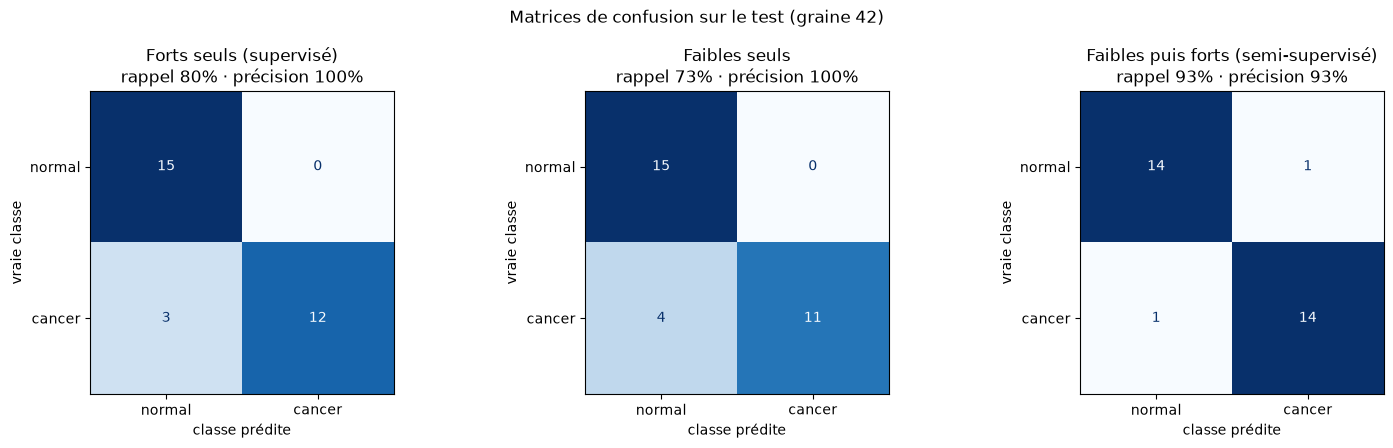

In [46]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, r in zip(axes, resultats):
    matrice = np.array(r["matrice [[VN, FP], [FN, VP]]"])
    ConfusionMatrixDisplay(matrice, display_labels=["normal", "cancer"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{r['approche']}\nrappel {r['rappel']:.0%} · précision {r['précision']:.0%}")
    ax.set_xlabel("classe prédite")
    ax.set_ylabel("vraie classe")
fig.suptitle("Matrices de confusion sur le test (graine 42)")
plt.tight_layout()
plt.show()


Avec la graine 42 : « forts seuls » rate 3 cancers sur 15, sans fausse alerte ; « faibles seuls » en rate 4, sans fausse alerte ; « faibles puis forts » n'en rate qu'un, au prix d'une fausse alerte. Les erreurs à surveiller en priorité sont celles de la case en bas à gauche (cancers ratés).

## 5. Robustesse : 10 graines

Les résultats dépendent du hasard (poids de départ de la tête, ordre des lots). On répète les trois approches avec 10 graines différentes, sans rien changer d'autre au protocole. Ce n'est pas une fuite de données : on ne choisit aucun réglage, on mesure seulement la stabilité des résultats.

rappel        précision            F2       
                     mean    std      mean    std   mean    std
approche                                                       
Faibles puis forts  0.880  0.028     0.937  0.022  0.891  0.023
Faibles seuls       0.747  0.028     1.000  0.000  0.786  0.025
Forts seuls         0.867  0.000     0.986  0.030  0.888  0.005

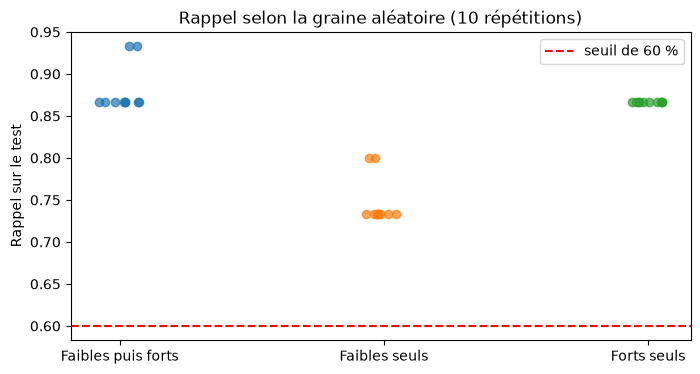

In [47]:
import matplotlib.pyplot as plt

repetitions = []
for graine in range(10):
    tete_forts = creer_tete(graine)
    entrainer(tete_forts, X_fort, y_fort, epoques=50, lr=1e-3, graine=graine)
    repetitions.append({**evaluer(tete_forts, "Forts seuls"), "graine": graine})

    tete_semi = creer_tete(graine)
    entrainer(tete_semi, X_faible, y_faible, epoques=10, lr=1e-3, graine=graine)
    repetitions.append({**evaluer(tete_semi, "Faibles seuls"), "graine": graine})
    entrainer(tete_semi, X_fort, y_fort, epoques=50, lr=1e-4, graine=graine)
    repetitions.append({**evaluer(tete_semi, "Faibles puis forts"), "graine": graine})

rep = pd.DataFrame(repetitions)
resume = rep.groupby("approche")[["rappel", "précision", "F2"]].agg(["mean", "std"]).round(3)
display(resume)

# Visualisation : le rappel obtenu avec chaque graine, par approche
fig, ax = plt.subplots(figsize=(8, 4))
for k, (nom, groupe) in enumerate(rep.groupby("approche")):
    ax.scatter(np.full(len(groupe), k) + np.random.uniform(-0.08, 0.08, len(groupe)), groupe["rappel"], alpha=0.7)
ax.set_xticks(range(rep["approche"].nunique()), sorted(rep["approche"].unique()))
ax.axhline(0.60, color="red", linestyle="--", label="seuil de 60 %")
ax.set_ylabel("Rappel sur le test")
ax.set_title("Rappel selon la graine aléatoire (10 répétitions)")
ax.legend()
plt.show()


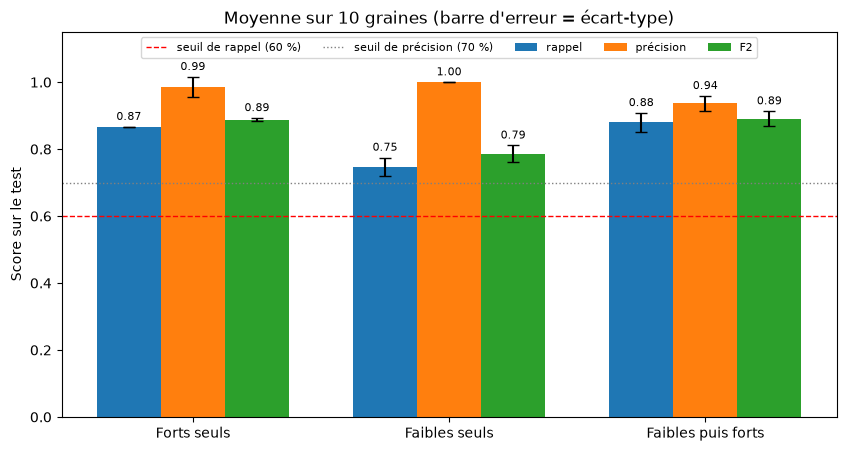

In [48]:
ordre = ["Forts seuls", "Faibles seuls", "Faibles puis forts"]
metriques = ["rappel", "précision", "F2"]
moyennes = rep.groupby("approche")[metriques].mean().loc[ordre]
ecarts = rep.groupby("approche")[metriques].std().loc[ordre]

x = np.arange(len(ordre))           # une position par approche : 0, 1, 2
largeur = 0.25                      # largeur de chaque barre
fig, ax = plt.subplots(figsize=(10, 5))
for k, m in enumerate(metriques):
    barres = ax.bar(x + (k - 1) * largeur, moyennes[m], largeur, yerr=ecarts[m], capsize=4, label=m)
    ax.bar_label(barres, fmt="%.2f", padding=3, fontsize=8)
ax.axhline(0.60, color="red", linestyle="--", linewidth=1, label="seuil de rappel (60 %)")
ax.axhline(0.70, color="gray", linestyle=":", linewidth=1, label="seuil de précision (70 %)")
ax.set_xticks(x, ordre)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Score sur le test")
ax.set_title("Moyenne sur 10 graines (barre d'erreur = écart-type)")
ax.legend(loc="upper center", ncol=5, fontsize=8)
plt.show()

Sur 10 graines, « forts seuls » et « faibles puis forts » sont équivalents (rappel 0,87 et 0,88, F2 0,89) et satisfont la definition of done (rappel > 60 %, précision > 70 %). « Faibles seuls » est nettement en retrait (rappel 0,75). « Forts seuls » est le plus stable : même rappel pour toutes les graines (13 cancers sur 15). Les barres d'erreur ne mesurent que la variabilité due au hasard de l'entraînement : l'incertitude liée à la petite taille du test (30 images) est plus grande.

## 6. Optimisation des hyperparamètres

Les réglages de la section 4 (tête linéaire, lr = 0,001, L2 = 0,0001, 50 epochs) étaient fixés à l'avance et justifiés, mais jamais comparés à d'autres. On les compare ici **sans utiliser le test**, réservé à l'évaluation finale : le choix se fait à l'intérieur des 69 images fortes, par **validation croisée stratifiée répétée**.

- **5 plis stratifiés** : chaque pli de validation garde la proportion de cancers, et chaque image passe exactement une fois en validation.
- **Répétée 3 fois**, avec d'autres découpages, soit 15 couples (train, validation) : un pli ne contient qu'environ 14 images, donc un score isolé est très instable.
- **Les mêmes plis pour toutes les configurations** : la seule différence entre deux configurations est leurs réglages, pas la difficulté des plis. La graine de la tête est le numéro du pli, ce qui inclut le hasard de l'initialisation dans l'écart-type.
- **Le nombre d'epochs** est choisi par **arrêt anticipé** : à chaque epoch, on mesure la perte sur le pli de validation ; après 20 epochs sans amélioration, on arrête et on revient aux meilleurs poids.


In [49]:
from sklearn.model_selection import RepeatedStratifiedKFold

# 5 plis, répétés 3 fois avec des découpages différents -> 15 couples (train, validation)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

# On crée les plis UNE SEULE FOIS et on les garde dans une liste
plis = list(cv.split(X_fort, y_fort))

print("Nombre de plis :", len(plis))
for num, (idx_tr, idx_val) in enumerate(plis[:5]):   # la 1re répétition seulement
    print(f"Pli {num} : {len(idx_tr)} train / {len(idx_val)} validation, "
          f"dont {y_fort[idx_val].sum()} cancers en validation")

Nombre de plis : 15
Pli 0 : 55 train / 14 validation, dont 7 cancers en validation
Pli 1 : 55 train / 14 validation, dont 7 cancers en validation
Pli 2 : 55 train / 14 validation, dont 7 cancers en validation
Pli 3 : 55 train / 14 validation, dont 7 cancers en validation
Pli 4 : 56 train / 13 validation, dont 7 cancers en validation


On obtient 15 plis de 55 images d'entraînement et 14 de validation (13 pour un pli sur cinq, car 69 n'est pas divisible par 5), avec 7 cancers dans chaque pli de validation. Un cancer raté dans un pli coûte donc 14 points de rappel : on lit toujours la moyenne et l'écart-type des 15 plis.


In [50]:
def mesurer(tete, X, y):
    """Rappel, précision et F2 de la tête sur (X, y)."""
    tete.eval()
    with torch.no_grad():
        y_pred = tete(torch.tensor(X, dtype=torch.float32)).argmax(dim=1).numpy()
    return {
        "rappel": recall_score(y, y_pred, zero_division=0),
        "précision": precision_score(y, y_pred, zero_division=0),
        "F2": fbeta_score(y, y_pred, beta=2, zero_division=0),
    }

def evaluer_config(lr, weight_decay, cachee, dropout, X=None):
    """Entraîne et mesure une configuration sur les 15 plis. Renvoie une ligne par pli.
    X : embeddings des 69 images fortes (par défaut X_fort, ceux de la section 1)."""
    X = X_fort if X is None else X
    lignes = []
    for num_pli, (idx_tr, idx_val) in enumerate(plis):
        tete = creer_tete(graine=num_pli, cachee=cachee, dropout=dropout)
        nb_epoques = entrainer(tete, X[idx_tr], y_fort[idx_tr], epoques=300, lr=lr,
                               graine=num_pli, weight_decay=weight_decay,
                               X_val=X[idx_val], y_val=y_fort[idx_val])
        lignes.append({"pli": num_pli, "époques": nb_epoques,
                       **mesurer(tete, X[idx_val], y_fort[idx_val])})
    return lignes



`mesurer` calcule rappel, précision et F2 sur n'importe quel jeu, ici un pli de validation (`evaluer` reste réservée au test). `evaluer_config` entraîne une configuration sur les 15 plis, avec arrêt anticipé, et renvoie une ligne par pli. On la teste d'abord sur les réglages de la baseline : un contrôle de cohérence avant de lancer la grille complète.


In [51]:
%%time
essai = pd.DataFrame(evaluer_config(lr=1e-3, weight_decay=1e-4, cachee=None, dropout=0.0))
essai.drop(columns="pli").agg(["mean", "std", "median"]).round(2)

CPU times: user 313 ms, sys: 82.7 ms, total: 396 ms
Wall time: 401 ms


,époques,rappel,précision,F2
mean,39.87,0.83,0.92,0.84
std,77.65,0.12,0.08,0.11
median,5.00,0.86,0.88,0.86


In [52]:
essai

,pli,époques,rappel,précision,F2
0,0,300,1.000000,1.000000,1.000000
1,1,20,0.714286,0.833333,0.735294
2,2,19,0.714286,0.833333,0.735294
3,3,4,0.857143,1.000000,0.882353
4,4,3,0.857143,1.000000,0.882353
5,5,29,1.000000,1.000000,1.000000
6,6,84,1.000000,0.875000,0.972222
7,7,1,0.714286,0.833333,0.735294
8,8,5,0.571429,1.000000,0.625000
9,9,5,0.857143,0.857143,0.857143


Contrôle réussi : avec les réglages de la baseline, le F2 moyen en validation croisée (0,84 ± 0,11) est du même ordre que sur le test, et l'arrêt anticipé fonctionne. Les epochs retenues sont très dispersées (médiane 5, moyenne 40) :
- la plupart des plis s'arrêtent avant 10 epochs : la perte de validation remonte très tôt, par **surconfiance**. En continuant l'entraînement, la tête pousse ses probabilités vers 0 ou 1 ; une image ratée le devient avec assurance et sa perte explose (−log(0,18) ≈ 1,7, mais −log(0,001) ≈ 6,9), même si le nombre d'erreurs, donc le F2, ne change pas ;
- le pli 0 n'a aucune erreur de validation : aucune image ratée ne fait remonter la perte, qui baisse jusqu'au plafond de 300 epochs.


La perte de validation peut remonter alors que le F2 ne bouge pas : l'arrêt anticipé coupe-t-il trop tôt ? On le compare directement aux 50 epochs fixes de la baseline, sur les mêmes plis.

In [53]:
lignes = []
for num_pli, (idx_tr, idx_val) in enumerate(plis):
    Xtr, ytr = X_fort[idx_tr], y_fort[idx_tr]
    Xv, yv = X_fort[idx_val], y_fort[idx_val]

    # a) avec arrêt anticipé
    tete = creer_tete(graine=num_pli)
    nb = entrainer(tete, Xtr, ytr, epoques=300, lr=1e-3, graine=num_pli, X_val=Xv, y_val=yv)
    f2_anticipe = mesurer(tete, Xv, yv)["F2"]

    # b) 50 epochs fixes, comme la baseline
    tete = creer_tete(graine=num_pli)
    entrainer(tete, Xtr, ytr, epoques=50, lr=1e-3, graine=num_pli)
    f2_fixe = mesurer(tete, Xv, yv)["F2"]

    lignes.append({"pli": num_pli, "époques_retenues": nb,
                   "F2_anticipé": f2_anticipe, "F2_50_fixes": f2_fixe})

comparaison = pd.DataFrame(lignes)
display(comparaison.round(2))
comparaison[["F2_anticipé", "F2_50_fixes"]].agg(["mean", "std", "median"]).round(2)


,pli,époques_retenues,F2_anticipé,F2_50_fixes
0,0,300,1.00,1.00
1,1,20,0.74,0.74
2,2,19,0.74,0.74
3,3,4,0.88,0.88
4,4,3,0.88,0.88
5,5,29,1.00,0.76
6,6,84,0.97,0.97
7,7,1,0.74,0.61
8,8,5,0.62,0.62
9,9,5,0.86,0.74


,F2_anticipé,F2_50_fixes
mean,0.84,0.80
std,0.11,0.11
median,0.86,0.76


L'arrêt anticipé obtient un F2 moyen de 0,84, contre 0,80 pour les 50 epochs fixes, et ne perd sur aucun pli : 11 plis à égalité (mêmes erreurs à l'epoch 5 et à l'epoch 50) et 4 plis où il gagne (5, 7, 9 et 10), car en continuant, la tête finit par faire basculer une ou deux images du mauvais côté. Prudent sans rien coûter : on le retient pour la grille.

La grille compare 27 configurations, chacune sur les mêmes 15 plis avec arrêt anticipé, soit 405 entraînements :
- taux d'apprentissage : 0,0001, 0,001 et 0,01 ;
- régularisation L2 (`weight_decay`) : 0, 0,0001 et 0,001 ;
- tête : linéaire (baseline), ou une couche cachée de 256 neurones avec dropout de 0,2 ou 0,5.

Le nom de la tête est stocké en texte : avec `cachee=None`, `groupby` aurait supprimé sans prévenir les lignes des têtes linéaires (clé manquante).

In [54]:
%%time
import itertools

taux = [1e-4, 1e-3, 1e-2]
l2 = [0.0, 1e-4, 1e-3]
tetes = [(None, 0.0), (256, 0.2), (256, 0.5)]      # (couche cachée, dropout)

lignes = []
for lr, wd, (cachee, dropout) in itertools.product(taux, l2, tetes):
    nom_tete = "linéaire" if cachee is None else f"256 + dropout {dropout}"
    for ligne in evaluer_config(lr, wd, cachee, dropout):
        lignes.append({"lr": lr, "L2": wd, "tête": nom_tete, **ligne})

grille = pd.DataFrame(lignes)
synthese = (grille.groupby(["lr", "L2", "tête"])
                  .agg(F2_moy=("F2", "mean"), F2_std=("F2", "std"),
                       rappel_moy=("rappel", "mean"), précision_moy=("précision", "mean"),
                       époques_méd=("époques", "median"))
                  .sort_values("F2_moy", ascending=False)
                  .round(3))
synthese.head(30)


CPU times: user 1min 1s, sys: 7.04 s, total: 1min 8s
Wall time: 42.2 s


F2_moy  F2_std  rappel_moy  précision_moy  \
lr     L2     tête                                                           
0.0100 0.0000 256 + dropout 0.5   0.938   0.076       0.943          0.932   
0.0010 0.0010 256 + dropout 0.5   0.938   0.090       0.943          0.928   
0.0100 0.0010 256 + dropout 0.5   0.931   0.103       0.933          0.940   
       0.0001 256 + dropout 0.5   0.931   0.103       0.933          0.940   
0.0010 0.0001 256 + dropout 0.5   0.914   0.100       0.914          0.927   
       0.0000 256 + dropout 0.5   0.914   0.100       0.914          0.927   
0.0100 0.0010 256 + dropout 0.2   0.890   0.145       0.895          0.889   
       0.0001 256 + dropout 0.2   0.890   0.145       0.895          0.889   
       0.0000 256 + dropout 0.2   0.890   0.145       0.895          0.889   
0.0010 0.0010 256 + dropout 0.2   0.880   0.146       0.876          0.923   
       0.0000 256 + dropout 0.2   0.880   0.146       0.876          0.923   
       0.0001 256 + dropout 0.2   0.880   0.146       0.876          0.923   
0.0001 0.0010 256 + dropout 0.2   0.866   0.125       0.857          0.919   
              256 + dropout 0.5   0.858   0.120       0.848          0.919   
       0.0000 256 + dropout 0.2   0.850   0.122       0.838          0.919   
              256 + dropout 0.5   0.850   0.122       0.838          0.919   
       0.0001 256 + dropout 0.5   0.850   0.122       0.838          0.919   
              256 + dropout 0.2   0.850   0.122       0.838          0.919   
0.0100 0.0000 linéaire            0.850   0.122       0.838          0.919   
       0.0001 linéaire            0.850   0.122       0.838          0.919   
       0.0010 linéaire            0.850   0.122       0.838          0.919   
0.0010 0.0001 linéaire            0.842   0.107       0.829          0.920   
       0.0010 linéaire            0.842   0.107       0.829          0.920   
       0.0000 linéaire            0.842   0.107       0.829          0.920   
0.0001 0.0010 linéaire            0.818   0.126       0.800          0.914   
       0.0001 linéaire            0.818   0.126       0.800          0.914   
       0.0000 linéaire            0.818   0.126       0.800          0.914   

                                 époques_méd  
lr     L2     tête                            
0.0100 0.0000 256 + dropout 0.5          3.0  
0.0010 0.0010 256 + dropout 0.5          8.0  
0.0100 0.0010 256 + dropout 0.5          3.0  
       0.0001 256 + dropout 0.5          3.0  
0.0010 0.0001 256 + dropout 0.5          7.0  
       0.0000 256 + dropout 0.5          7.0  
0.0100 0.0010 256 + dropout 0.2          2.0  
       0.0001 256 + dropout 0.2          2.0  
       0.0000 256 + dropout 0.2          2.0  
0.0010 0.0010 256 + dropout 0.2          3.0  
       0.0000 256 + dropout 0.2          3.0  
       0.0001 256 + dropout 0.2          3.0  
0.0001 0.0010 256 + dropout 0.2        203.0  
              256 + dropout 0.5        190.0  
       0.0000 256 + dropout 0.2        300.0  
              256 + dropout 0.5        235.0  
       0.0001 256 + dropout 0.5        193.0  
              256 + dropout 0.2        300.0  
0.0100 0.0000 linéaire                   2.0  
       0.0001 linéaire                   2.0  
       0.0010 linéaire                   2.0  
0.0010 0.0001 linéaire                   5.0  
       0.0010 linéaire                   5.0  
       0.0000 linéaire                   5.0  
0.0001 0.0010 linéaire                 291.0  
       0.0001 linéaire                 291.0  
       0.0000 linéaire                 291.0

Trois enseignements :
- **Le dropout 0,5 domine** : il occupe les 6 premières places (F2 de 0,914 à 0,938), devant le dropout 0,2, puis la tête linéaire.
- **Le petit taux d'apprentissage est le pire** (F2 de 0,818 pour la tête linéaire à lr = 0,0001) : la descente est si lente que l'entraînement atteint presque le plafond (médiane de 291 epochs). Le grand taux (0,01) devient surconfiant en 2 ou 3 epochs, mais l'arrêt anticipé le rattrape.
- **La L2 n'a quasiment aucun effet** : de nombreuses lignes sont identiques à la L2 près. Avec 2 à 8 epochs (4 à 16 pas), elle n'a pas le temps d'agir ; l'arrêt anticipé joue déjà le rôle de garde-fou contre le surapprentissage.

Selon la règle « écart < écart-type », l'écart entre la meilleure configuration et la baseline (0,938 contre 0,842, pour ± 0,10) ne serait pas concluant. Mais toutes les configurations ont passé les mêmes plis : on peut les comparer **pli par pli**.

La comparaison pli par pli soustrait les F2 de deux configurations sur chaque pli : un pli difficile pour les deux donne un écart nul, la difficulté commune s'annule, et il ne reste que l'effet des réglages. On compare les deux premières configurations à la baseline, puis entre elles.

In [55]:
def par_pli(lr, l2, tete, colonne="F2"):
    """Valeur d'une colonne (F2, précision, époques…) pour chaque pli d'une configuration."""
    sel = grille[(grille["lr"] == lr) & (grille["L2"] == l2) & (grille["tête"] == tete)]
    return sel.set_index("pli")[colonne]

def comparer(candidat, reference):
    """Compare deux configurations pli par pli sur le F2. Chaque configuration = (lr, L2, tête)."""
    ecart = par_pli(*candidat) - par_pli(*reference)      # le * déballe le tuple en 3 arguments
    return {
        "écart moyen": round(ecart.mean(), 3),
        "mieux": (ecart > 0).sum(),
        "égal": (ecart == 0).sum(),
        "moins bien": (ecart < 0).sum(),
    }

baseline = (1e-3, 1e-4, "linéaire")
n1 = (1e-2, 0.0, "256 + dropout 0.5")
n2 = (1e-3, 1e-3, "256 + dropout 0.5")

# 1) Chacune face à la baseline, puis l'une face à l'autre
duels = pd.DataFrame({
    "n° 1 vs baseline": comparer(n1, baseline),
    "n° 2 vs baseline": comparer(n2, baseline),
    "n° 1 vs n° 2": comparer(n1, n2),
}).T
display(duels)

# 2) Le profil de chaque configuration
profils = pd.DataFrame({
    nom: {
        "F2 moyen": par_pli(*config).mean(),
        "F2 écart-type": par_pli(*config).std(),
        "F2 le plus bas": par_pli(*config).min(),
        "précision la plus basse": par_pli(*config, colonne="précision").min(),
        "époques (médiane)": par_pli(*config, colonne="époques").median(),
    }
    for nom, config in {"baseline": baseline, "n° 1": n1, "n° 2": n2}.items()
}).T.round(3)
profils


,écart moyen,mieux,égal,moins bien
n° 1 vs baseline,0.096,9.0,5.0,1.0
n° 2 vs baseline,0.095,8.0,7.0,0.0
n° 1 vs n° 2,0.000,2.0,12.0,1.0


,F2 moyen,F2 écart-type,F2 le plus bas,précision la plus basse,époques (médiane)
baseline,0.842,0.107,0.625,0.833,5.0
n° 1,0.938,0.076,0.758,0.750,3.0
n° 2,0.938,0.090,0.735,0.833,8.0


La couche cachée avec dropout 0,5 bat la tête linéaire de façon régulière : la n° 2 fait mieux que la baseline sur 8 plis, aussi bien sur 7, et jamais moins bien.

Les deux meilleures configurations sont à égalité sur 12 plis sur 15. On retient celle qui ne fait jamais moins bien que la baseline et dont la précision la plus basse reste à 0,83, contre 0,75 pour l'autre, tout près du seuil de 70 %. Elle garde aussi le taux d'apprentissage de la baseline : le seul vrai changement est la couche cachée avec dropout 0,5.

**Configuration retenue** : lr = 0,001, L2 = 0,001, couche cachée de 256 neurones, dropout 0,5.

## 7. Évaluation finale sur le test

La configuration retenue est réentraînée sur les 69 images fortes, avec le nombre d'epochs médian trouvé en validation croisée, puis évaluée **une seule fois** sur le test, sur 10 graines comme la baseline. Sur 69 images, une epoch compte 3 lots de 32 au lieu de 2 : les 8 epochs font 24 pas au lieu de 16, ce qui est la convention (chaque image est vue le même nombre de fois).


In [56]:
# Configuration retenue par validation croisée
LR, L2, CACHEE, DROPOUT = 1e-3, 1e-3, 256, 0.5
EPOQUES = int(synthese.loc[(LR, L2, "256 + dropout 0.5"), "époques_méd"])
print("Epochs retenues :", EPOQUES)

# 10 graines, comme pour la baseline : on vérifie que le résultat ne dépend pas du hasard
finale = []
for graine in range(10):
    tete = creer_tete(graine=graine, cachee=CACHEE, dropout=DROPOUT)
    entrainer(tete, X_fort, y_fort, epoques=EPOQUES, lr=LR, graine=graine, weight_decay=L2)
    finale.append({**evaluer(tete, "Forts seuls · tête optimisée"), "graine": graine})

pd.DataFrame(finale)[["rappel", "précision", "F2"]].agg(["mean", "std"]).round(3)


Epochs retenues : 8


,rappel,précision,F2
mean,0.867,0.957,0.883
std,0.000,0.037,0.006


Rappel 0,867 ± 0, précision 0,957, F2 0,883 : comme la baseline (0,867 / 0,986 / 0,888), la tête optimisée trouve 13 cancers sur 15. Le gain observé en validation croisée ne se voit pas sur le test. Ce n'est pas contradictoire : avec 15 cancers, un cancer vaut 6,7 points de rappel, et le test est trop petit pour mesurer un gain de cette taille.

La tête optimisée est conservée, car elle a été choisie avant d'ouvrir le test : revenir à la baseline sur la foi du test (0,888 contre 0,883) reviendrait à utiliser le test pour choisir. Le test indique seulement qu'il n'y a pas de dégradation.

Limite : l'arrêt anticipé choisit l'epoch sur le pli de validation qui sert aussi à noter la tête ; les scores de validation croisée sont donc légèrement optimistes. C'est acceptable pour comparer les configurations entre elles, puisqu'elles ont toutes le même avantage, et le score final vient du test, intouché.


## 8. Les cancers ratés

La baseline et la tête optimisée ratent toutes deux 2 cancers sur 15. On regarde la probabilité que la tête leur attribue et à quoi ils ressemblent. `inventaire[masque_test]` est dans le même ordre que `X_test` (le même masque est appliqué aux mêmes lignes), ce qui permet de rattacher chaque probabilité à son image.


,chemin,proba_cancer
18,../avec_labels/cancer/7e3f6acd-c9cc-440e-ba01-...,0.005845
22,../avec_labels/cancer/9973120d-7335-43da-bd9b-...,0.007608


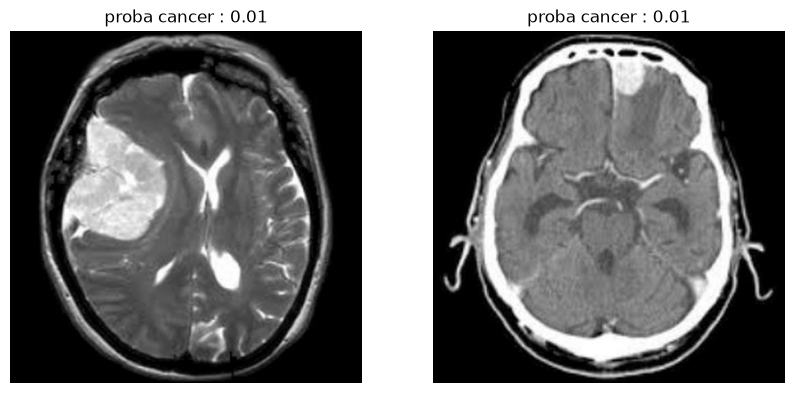

In [57]:
# Une tête optimisée (graine 0) : quelles probabilités donne-t-elle aux images du test ?
tete = creer_tete(graine=0, cachee=CACHEE, dropout=DROPOUT)
entrainer(tete, X_fort, y_fort, epoques=EPOQUES, lr=LR, graine=0, weight_decay=L2)
tete.eval()
with torch.no_grad():
    scores = tete(torch.tensor(X_test, dtype=torch.float32))
proba_cancer = torch.softmax(scores, dim=1)[:, 1].numpy()    # colonne 1 = probabilité « cancer »

test_df = inventaire[masque_test].copy()                       # même ordre que X_test
test_df["proba_cancer"] = proba_cancer
rates = test_df[(test_df["label"] == "cancer") & (test_df["proba_cancer"] < 0.5)]
display(rates[["chemin", "proba_cancer"]])

from PIL import Image
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, len(rates), figsize=(5 * len(rates), 5))
for ax, (_, ligne) in zip(np.atleast_1d(axes), rates.iterrows()):
    ax.imshow(Image.open(ligne["chemin"]), cmap="gray")
    ax.set_title(f"proba cancer : {ligne['proba_cancer']:.2f}")
    ax.axis("off")
plt.show()


Les deux cancers ratés sont des **erreurs assurées** : la tête leur attribue 0,6 % et 0,8 % de probabilité de cancer. Un seuil de confiance, qui enverrait les images incertaines au radiologue, ne les rattraperait pas : il faut aussi un contrôle qualité par échantillonnage aléatoire des images classées « normales ».

Les deux images sont des **coupes axiales**, l'orientation de 98 % des normaux contre 66 % des cancers. C'est cohérent avec le biais d'orientation repéré à l'étape 1 : le modèle a pu apprendre « coupe axiale → normal ». La première image montre pourtant une lésion très visible : pour elle, le modèle ne s'appuie manifestement pas sur la tumeur. Deux images ne prouvent rien, mais la piste est concrète : mesurer le rappel séparément sur les coupes axiales et non axiales.


## 9. Égalisation d'histogramme : effet sur la tête

Les embeddings des trois variantes d'égalisation (notebook 02, section 3.2) sont comparés aux embeddings d'origine, sans utiliser le test, avec le protocole de la section 6 : mêmes 15 plis, arrêt anticipé, comparaison pli par pli. Pour chaque variante, le scaler est ajusté sur les images fortes et faibles de cette variante, jamais sur le test.

L'égalisation modifierait toute la chaîne en aval (ACP, clustering, labels faibles, trois approches). On la teste donc d'abord sur la tête entraînée avec les seules 69 images fortes ; la chaîne complète ne serait relancée qu'en cas de gain net. Deux têtes sont testées : la tête retenue à la section 6, et la baseline linéaire, dont les réglages, fixés à la main, n'ont été optimisés pour aucun jeu d'embeddings.

In [58]:
def charger_X_fort(fichier):
    """Embeddings des 69 images fortes pour une variante, standardisés comme à la section 1
    (scaler ajusté sur forts + faibles de cette variante, jamais sur le test)."""
    emb = np.load(fichier)
    assert emb.shape == embeddings.shape                  # même nombre d'images, même ordre
    Xf, Xw = emb[masque_train], emb[faibles["ligne"].to_numpy()]
    scaler_var = StandardScaler().fit(np.vstack([Xf, Xw]))
    return scaler_var.transform(Xf)

variantes = {
    "aucune": "../data/embeddings.npy",
    "A. globale": "../data/embeddings_globale.npy",
    "B. masque": "../data/embeddings_masque.npy",
    "C. CLAHE": "../data/embeddings_clahe.npy",
}
tetes_testees = {
    "baseline (linéaire)": (1e-3, 1e-4, None, 0.0),
    "retenue (256 + dropout 0,5)": (LR, L2, CACHEE, DROPOUT),
}

lignes = []
for nom_var, fichier in variantes.items():
    X_var = charger_X_fort(fichier)
    for nom_tete, (lr, wd, cachee, dropout) in tetes_testees.items():
        for ligne in evaluer_config(lr, wd, cachee, dropout, X=X_var):
            lignes.append({"égalisation": nom_var, "tête": nom_tete, **ligne})

egal = pd.DataFrame(lignes)
egal.groupby(["tête", "égalisation"])[["F2", "rappel", "précision"]].agg(["mean", "std"]).round(3)


F2        rappel        précision  \
                                          mean    std   mean    std      mean   
tête                        égalisation                                         
baseline (linéaire)         A. globale   0.814  0.139  0.790  0.161     0.960   
                            B. masque    0.748  0.178  0.714  0.195     0.977   
                            C. CLAHE     0.745  0.148  0.714  0.162     0.944   
                            aucune       0.842  0.107  0.829  0.123     0.920   
retenue (256 + dropout 0,5) A. globale   0.887  0.092  0.876  0.106     0.942   
                            B. masque    0.894  0.103  0.886  0.123     0.945   
                            C. CLAHE     0.871  0.135  0.857  0.153     0.947   
                            aucune       0.938  0.090  0.943  0.105     0.928   

                                                
                                           std  
tête                        égalisation         
baseline (linéaire)         A. globale   0.069  
                            B. masque    0.061  
                            C. CLAHE     0.083  
                            aucune       0.078  
retenue (256 + dropout 0,5) A. globale   0.074  
                            B. masque    0.071  
                            C. CLAHE     0.080  
                            aucune       0.071

Contrôle de non-régression : sans égalisation, on retrouve les F2 de validation croisée de la section 6 (0,842 pour la baseline, 0,938 pour la tête retenue). Les trois variantes font moins bien que les embeddings d'origine, avec les deux têtes : F2 de 0,745 à 0,814 pour la baseline, de 0,871 à 0,894 pour la tête retenue.

In [59]:
duels_egal = {}
for nom_tete in tetes_testees:
    reference = egal[(egal["tête"] == nom_tete) & (egal["égalisation"] == "aucune")].set_index("pli")["F2"]
    for nom_var in ["A. globale", "B. masque", "C. CLAHE"]:
        variante = egal[(egal["tête"] == nom_tete) & (egal["égalisation"] == nom_var)].set_index("pli")["F2"]
        ecart = variante - reference
        duels_egal[(nom_tete, nom_var)] = {"écart moyen": round(ecart.mean(), 3), "mieux": (ecart > 0).sum(),
                                           "égal": (ecart == 0).sum(), "moins bien": (ecart < 0).sum()}
pd.DataFrame(duels_egal).T

écart moyen  mieux  égal  moins bien
baseline (linéaire)         A. globale       -0.028    6.0   2.0         7.0
                            B. masque        -0.095    5.0   3.0         7.0
                            C. CLAHE         -0.097    2.0   1.0        12.0
retenue (256 + dropout 0,5) A. globale       -0.051    3.0   5.0         7.0
                            B. masque        -0.044    1.0   8.0         6.0
                            C. CLAHE         -0.067    2.0   6.0         7.0

La comparaison pli par pli confirme la tendance : aucune variante ne fait mieux que les embeddings d'origine. CLAHE est la plus pénalisante avec la baseline (moins bien sur 12 plis sur 15) ; la variante B, la plus convaincante à l'œil, perd elle aussi (− 0,095 de F2 avec la baseline, − 0,044 avec la tête retenue). L'aspect visuel ne prédit pas l'utilité pour ResNet.

**L'égalisation n'est pas retenue**, et le test n'est donc pas utilisé.

Hypothèses :
- ResNet, appris sur des photos naturelles, réagit mal aux textures créées par l'égalisation (bruit amplifié, zones saturées) ;
- l'égalisation efface l'intensité absolue, qui peut distinguer une tumeur ;
- le contraste d'origine pourrait porter un raccourci (machine, séquence d'acquisition), comme l'orientation : l'égalisation le supprimerait, et un score plus bas ne signifierait pas alors un moins bon modèle. Les 69 images ne permettent pas de trancher.

Limite : la tête retenue a été réglée sur les embeddings d'origine, ce qui pourrait désavantager les variantes égalisées ; mais la baseline, réglée à la main, conduit à la même conclusion.

## 10. Label spreading

Le label spreading construit un graphe où chaque image est reliée à ses k plus proches voisines, puis diffuse les 69 labels forts de proche en proche jusqu'à stabilisation. Contrairement au clustering Ward suivi d'un vote, il utilise les labels dès le départ, respecte la structure locale des données et fournit une confiance pour chaque image. Le graphe est construit sur les 100 premières composantes de l'ACP (apprise sur les images fortes et faibles, jamais sur le test), car en 2 048 dimensions les distances perdent leur sens.

In [60]:
from sklearn.decomposition import PCA
from sklearn.semi_supervised import LabelSpreading

# ACP à 100 composantes, apprise sur forts + faibles (jamais sur le test), comme pour Ward
acp = PCA(n_components=100, random_state=42).fit(np.vstack([X_fort, X_faible]))
Z_fort, Z_faible, Z_test = acp.transform(X_fort), acp.transform(X_faible), acp.transform(X_test)
Z = np.vstack([Z_fort, Z_faible])        # les 69 forts d'abord, puis les 1 311 sans label
print(f"Information conservée par 100 composantes : {acp.explained_variance_ratio_.sum():.0%}")

def propager(y_connus, k, alpha=0.2):
    """Label spreading sur le graphe des k plus proches voisins.
    y_connus : labels des 69 images fortes, -1 pour un label caché."""
    y = np.concatenate([y_connus, -np.ones(len(Z_faible), dtype=int)])   # -1 = « inconnu » pour scikit-learn
    return LabelSpreading(kernel="knn", n_neighbors=k, alpha=alpha, max_iter=1000).fit(Z, y)

# Une première propagation, avec les 69 labels
ls = propager(y_fort, k=10)
proba = ls.label_distributions_[len(Z_fort):]     # (1311, 2) : probabilités normal / cancer
pseudo = proba.argmax(axis=1)                      # pseudo-label : la classe la plus probable
confiance = proba.max(axis=1)                      # entre 0,5 et 1
print("Pseudo-labels : cancers", pseudo.sum(), "| normaux", (pseudo == 0).sum())
print(f"Accord avec les labels faibles de Ward : {(pseudo == y_faible).mean():.0%}")
print(f"Pseudo-labels avec une confiance > 0,9 : {(confiance > 0.9).mean():.0%}")


Information conservée par 100 composantes : 58%
Pseudo-labels : cancers 847 | normaux 464
Accord avec les labels faibles de Ward : 87%
Pseudo-labels avec une confiance > 0,9 : 87%


Première propagation (k = 10, alpha = 0,2) : 847 cancers et 464 normaux parmi les 1 311 images sans label, une répartition proche de celle de Ward (805 / 506). Les deux méthodes s'accordent sur 87 % des images, mais cet accord ne mesure pas la justesse : elles reposent sur les mêmes features et peuvent se tromper ensemble.

Pour mesurer la justesse des pseudo-labels, on cache les labels des images de validation de chaque pli, on propage, et on vérifie si on les retrouve. Les mêmes 15 plis servent à choisir le nombre de voisins k et le paramètre alpha (liberté laissée aux labels de départ d'être corrigés par leurs voisines).

In [61]:
lignes = []
for k in [5, 10, 20, 30, 50]:
    for alpha in [0.2, 0.5, 0.8]:
        for num_pli, (idx_tr, idx_val) in enumerate(plis):
            y_caches = y_fort.copy()
            y_caches[idx_val] = -1                          # on cache les labels du pli de validation
            ls_pli = propager(y_caches, k, alpha)
            retrouves = ls_pli.transduction_[idx_val]       # labels propagés sur les images cachées
            lignes.append({"k": k, "alpha": alpha, "pli": num_pli,
                           "justes": (retrouves == y_fort[idx_val]).mean(),
                           "rappel": recall_score(y_fort[idx_val], retrouves)})

qualite_ls = pd.DataFrame(lignes)
qualite_ls.groupby(["k", "alpha"])[["justes", "rappel"]].agg(["mean", "std"]).round(3)


justes        rappel       
           mean    std   mean    std
k  alpha                            
5  0.2    0.778  0.094  0.590  0.178
   0.5    0.812  0.093  0.686  0.155
   0.8    0.812  0.093  0.686  0.155
10 0.2    0.851  0.098  0.771  0.177
   0.5    0.856  0.089  0.781  0.161
   0.8    0.866  0.085  0.781  0.161
20 0.2    0.914  0.086  0.886  0.145
   0.5    0.909  0.083  0.876  0.141
   0.8    0.895  0.085  0.848  0.137
30 0.2    0.899  0.080  0.867  0.148
   0.5    0.894  0.080  0.857  0.132
   0.8    0.889  0.080  0.848  0.137
50 0.2    0.880  0.069  0.848  0.137
   0.5    0.880  0.069  0.848  0.137
   0.8    0.889  0.080  0.848  0.137

La part de labels retrouvés augmente avec k jusqu'à k = 20 (0,914 ± 0,086, rappel 0,886), puis redescend (0,899 pour k = 30, 0,880 pour k = 50) : k = 20 est un vrai sommet, et non un bord de grille. Alpha n'a qu'un effet secondaire. Avec k = 5, une seule voisine trompeuse pèse lourd ; avec k = 20, la diffusion moyenne davantage.

Comparaison avec Ward : ses labels faibles sont justes à 88 % (83 % des cancers retrouvés), mais cette mesure porte sur les 69 images qui ont servi à nommer les clusters par vote, ce qui l'avantage. Le label spreading, mesuré sur des labels cachés, est donc au moins aussi bon, en particulier sur le rappel, et il fournit en plus une confiance par image. Configuration retenue : k = 20, alpha = 0,2.

In [62]:
K, ALPHA = 20, 0.2      # choisis par validation croisée sur labels cachés, jamais sur le test
ls_final = propager(y_fort, K, ALPHA)

# a) Les pseudo-labels des 1 311 images sans label
proba_finale = ls_final.label_distributions_[len(Z_fort):]
pseudo_final = proba_finale.argmax(axis=1)
confiance_finale = proba_finale.max(axis=1)
print("Pseudo-labels : cancers", pseudo_final.sum(), "| normaux", (pseudo_final == 0).sum())
print(f"Confiance > 0,9 : {(confiance_finale > 0.9).mean():.0%} des images")

# b) Le label spreading comme classifieur direct, évalué une seule fois sur le test
pred_test = ls_final.predict(Z_test)
print(f"Test · rappel {recall_score(y_test, pred_test):.3f}"
      f" | précision {precision_score(y_test, pred_test, zero_division=0):.3f}"
      f" | F2 {fbeta_score(y_test, pred_test, beta=2):.3f}")
print("Matrice [[VN, FP], [FN, VP]] :", confusion_matrix(y_test, pred_test).tolist())


Pseudo-labels : cancers 829 | normaux 482
Confiance > 0,9 : 79% des images
Test · rappel 0.867 | précision 1.000 | F2 0.890
Matrice [[VN, FP], [FN, VP]] : [[15, 0], [2, 13]]


Avec la configuration retenue, 829 images sans label reçoivent le pseudo-label cancer et 482 le pseudo-label normal ; 79 % des pseudo-labels ont une confiance supérieure à 0,9.

Utilisé comme classifieur direct, le label spreading obtient sur le test un rappel de 0,867, une précision de 1,000 et un F2 de 0,890, équivalents à ceux de la tête de classification. Il est déterministe : pas besoin de répéter sur plusieurs graines. Les images de test ne font pas partie du graphe : chacune est classée d'après ses 20 plus proches voisines parmi les images déjà colorées, comme une nouvelle IRM le serait en production.

Les deux cancers ratés sont les mêmes que pour les têtes de classification, avec une probabilité de cancer nulle : leurs 20 voisines sont toutes normales. Trois méthodes différentes (tête linéaire, tête non linéaire, label spreading) commettent la même erreur avec la même assurance : la limite vient des features ResNet génériques, pas du classifieur. Pour ces deux coupes axiales, la tumeur ne se voit pas dans l'embedding.

Perspective : les pseudo-labels du label spreading, plus justes que ceux de Ward et accompagnés d'une confiance, pourraient remplacer les labels faibles dans l'approche « faibles puis forts », en ne gardant que les plus sûrs (la propagation devrait alors être refaite dans chaque pli, pour éviter une fuite).

## Conclusion de l'étape 4

**Protocole**, fixé avant de regarder le test : une tête de classification `Linear(2048, 2)` entraînée sur les embeddings ResNet-50 (backbone gelé), avec Adam et une légère régularisation.
- **Forts seuls** : 69 images, 50 epochs, lr = 0,001.
- **Faibles seuls** : 1 311 images (labels issus du clustering), 10 epochs, lr = 0,001.
- **Faibles puis forts** : le modèle précédent, puis 50 epochs sur les 69 images fortes, lr = 0,0001.

Toutes les approches sont évaluées sur le même test de 30 images (15 cancers), jamais utilisé auparavant.

| Approche (moyenne sur 10 graines) | Rappel | Précision | F2 |
|---|---|---|---|
| Forts seuls | 0,867 | 0,986 | 0,888 |
| Faibles seuls | 0,747 | 1,00 | 0,786 |
| Faibles puis forts | 0,880 | 0,937 | 0,891 |
| Forts seuls · tête optimisée | 0,867 | 0,957 | 0,883 |
| Label spreading (k = 20) · déterministe | 0,867 | 1,000 | 0,890 |

**Optimisation de la tête** (section 6) : 27 configurations comparées par validation croisée stratifiée répétée (5 plis × 3) sur les 69 images fortes, avec arrêt anticipé, sans utiliser le test. Une couche cachée de 256 neurones avec dropout 0,5 bat la tête linéaire de façon régulière (+ 0,10 de F2, aucun pli moins bien) ; la régularisation L2 n'a pas d'effet mesurable, l'arrêt anticipé jouant déjà ce rôle. Sur le test, ouvert une seule fois, elle obtient le même rappel que la baseline (13 cancers sur 15) : le test est trop petit pour confirmer le gain, mais il ne montre aucune dégradation.

**Prétraitement** (section 9) : trois variantes d'égalisation d'histogramme testées (globale, avec masque, CLAHE). Aucune ne fait mieux que les images d'origine en validation croisée, avec la tête de la baseline comme avec la tête retenue : l'égalisation n'est pas retenue.

**Label spreading** (section 10) : avec k = 20 voisins, les pseudo-labels retrouvent 91 % des labels cachés (rappel 0,886), au moins aussi bien que Ward (88 %, mesuré sur ses propres images de vote). Comme classifieur direct, il obtient sur le test un rappel de 0,867, une précision de 1,000 et un F2 de 0,890. Il rate les deux mêmes cancers que les têtes de classification, avec une probabilité nulle : la limite vient des features, pas du classifieur.


**Lecture**
- Les trois approches dépassent largement l'objectif de 60 % de rappel.
- Les labels faibles seuls font moins bien que 69 labels fiables.
- Avec la graine 42, « faibles puis forts » semblait meilleur (1 cancer raté contre 3), mais sur 10 graines, les deux approches sont équivalentes : l'écart initial était dû au hasard.
- Interprétation : grâce aux embeddings ResNet, le problème est déjà bien résolu avec 69 images ; les labels faibles (justes à environ 88 % sur le train 83% des cancers retrouvés) ajoutent du volume, mais aussi des erreurs.

**Definition of done** : ✅ atteinte. Rappel moyen de 0,87 à 0,88 et précision de 0,94 à 0,99 pour les deux meilleures approches ; comparaison répétée sur 10 graines ; test isolé depuis l'étape 1.

**Limites** : test de 30 images (un cancer = 6,7 points de rappel) ; taux d'apprentissage différent en phase 2 (convention du fine-tuning) ; biais du plan de coupe non corrigé. 
Les deux cancers ratés sont des coupes axiales, classées normales avec plus de 99 % d'assurance ; les approches avec labels faibles n'ont pas été relancées avec la tête optimisée ; scores de validation croisée légèrement optimistes (arrêt anticipé sur le pli qui sert à noter)

**Pistes** : labels faibles filtrés par un seuil de confiance ; « pseudo-labels du label spreading filtrés par confiance dans "faibles puis forts" ; évaluation sur les seules coupes axiales ; fine-tuning de `layer4`.
